# Member 2: Stationarity, Autocorrelation and Returns Analysis

**Target Stock:** Microsoft Corporation (MSFT)  
**Data Download Date:** 17 November 2026

This notebook examines the stationarity and statistical characteristics of Microsoft's (MSFT) historical stock prices and daily log returns.

The analysis uses the dataset prepared by Member 1. It applies rolling statistics, Augmented Dickey-Fuller (ADF) and KPSS tests to determine whether the closing price and log returns are stationary.

Additionally, the notebook investigates autocorrelation, volatility clustering and the effects of different transformations on the stock price series. The findings will help establish the appropriate data representation for subsequent forecasting models.

In [29]:
%pip install arch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import seasonal_decompose
import statsmodels.api as sm

from arch import arch_model

from tslab import config
from tslab.data import load_market_data
from tslab.plots import plot_acf_pacf

warnings.filterwarnings("ignore")

%matplotlib inline

plt.rcParams["figure.figsize"] = (12, 5)

print("Python version:", sys.version.split()[0])
print("Target stock:", config.TARGET_TICKER)

Python version: 3.12.10
Target stock: MSFT


### Loading The MSFT dataset

In [31]:
data = load_market_data()

price = data["Close"]
log_price = np.log(price)
price_change = price.diff().dropna()
log_return = log_price.diff().dropna()

print("Dataset shape:", data.shape)
print("Start date:", data.index.min())
print("End date:", data.index.max())

data.head()

Loaded 2981 trading days of MSFT, 2015-01-02 to 2026-11-09, with 7 predictor series.
Dataset shape: (2981, 12)
Start date: 2015-01-02 00:00:00
End date: 2026-11-09 00:00:00


,Open,High,Low,Close,Volume,SP500,TECH,VIX,US10Y,USD,BRENT,GOLD
Date,,,,,,,,,,,,
2015-01-02,39.522487,40.166230,39.420844,39.607189,27913900,2058.199951,18.041676,17.790001,2.123,91.080002,56.419998,1186.000000
2015-01-05,39.276844,39.581776,39.175202,39.242966,39673900,2020.579956,17.766277,19.920000,2.039,91.379997,53.110001,1203.900024
2015-01-06,39.285321,39.598722,38.573814,38.666988,36447900,2002.609985,17.552057,21.120001,1.963,91.500000,51.099998,1219.300049
2015-01-07,38.946499,39.353073,38.531455,39.158257,29114100,2025.900024,17.700701,19.309999,1.954,91.889999,51.150002,1210.599976
2015-01-08,39.598720,40.445751,39.573310,40.310226,29645200,2062.139893,18.089766,17.010000,2.016,92.370003,50.959999,1208.400024


### Visual analysis using a rolling stsatistics function

In [32]:
def plot_with_rolling(series, title, window=63):

    fig, (ax1, ax2) = plt.subplots(
        2, 1,
        figsize=(12, 7),
        sharex=True
    )

    ax1.plot(series, label=title)
    ax1.plot(
        series.rolling(window).mean(),
        color="red",
        label="Rolling Mean"
    )

    ax1.set_title(title)
    ax1.legend()

    ax2.plot(
        series.rolling(window).std(),
        color="green",
        label="Rolling Standard Deviation"
    )

    ax2.set_title("Rolling Standard Deviation")
    ax2.legend()

    plt.tight_layout()
    plt.show()

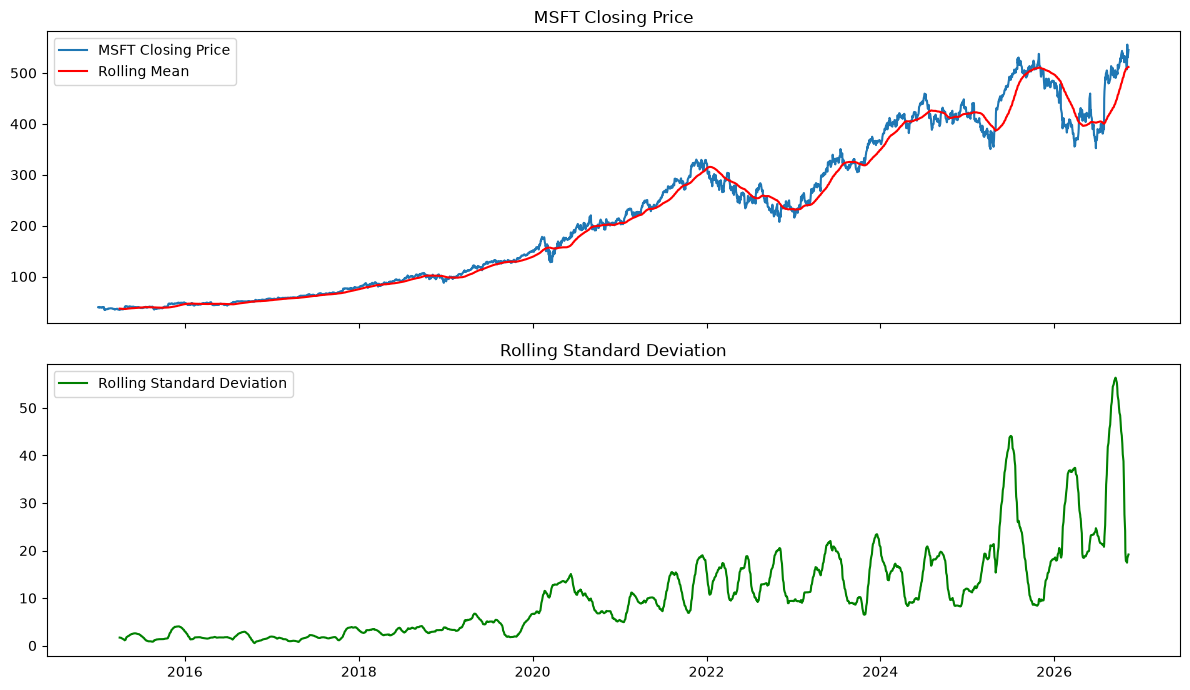

In [33]:
plot_with_rolling(price, "MSFT Closing Price")

The blue line represents Microsoft's actual daily closing prices.
The red line represents the 63-day rolling mean.
The green line in the lower plot represents the 63-day rolling standard deviation.

#### Interpretation 
1. The closing price generally increases from approximately $40 in 2015 to above $500 in 2026.
2. The red rolling mean follows the general upward movement of the stock price.
3. The rolling mean is not constant; it changes as the stock price increases and decreases.
4. The rolling standard deviation also changes considerably over time.
5. There are periods of particularly high variability, especially around 2020 and 2025–2026.
- These observations suggest that the closing price does not maintain a constant mean and variance, indicating that the series is likely non-stationary.

### Log returns

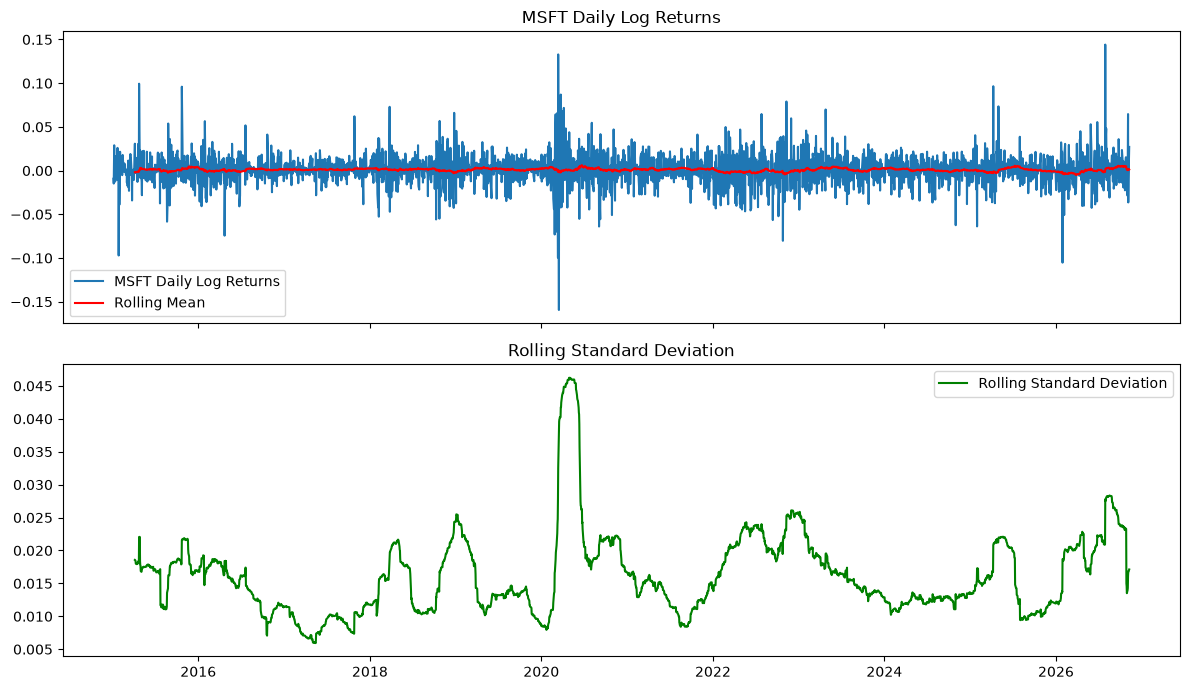

In [34]:
plot_with_rolling(log_return, "MSFT Daily Log Returns")

Blue line: Daily log returns.
Red line: 63-day rolling mean of log returns.
Green line: 63-day rolling standard deviation.

#### Interpretation
1. Unlike the closing price, daily log returns fluctuate around zero.
2. There is no clear long-term upward trend in the daily returns.
3. The red rolling mean stays relatively close to zero throughout the period.
4. However, the rolling standard deviation changes over time.
5. The most noticeable volatility increase occurs around 2020, where there are very large positive and negative returns.
6. Other periods of increased volatility are visible around 2022 and 2025–2026.

- Converting prices into log returns removes much of the upward trend observed in stock prices.
However, the variance of returns is not perfectly constant. This suggests that returns may be stationary in their mean but exhibit changing volatility.

- This is why you need both ADF and KPSS tests rather than relying on the graph alone.

### Defining the stationarity testing function

In [35]:
def stationarity_report(series, name):

    clean_series = series.dropna()

    adf_result = adfuller(
        clean_series,
        autolag="AIC"
    )

    kpss_result = kpss(
        clean_series,
        regression="c",
        nlags="auto"
    )

    adf_p = adf_result[1]
    kpss_p = kpss_result[1]

    if adf_p < 0.05 and kpss_p >= 0.05:
        verdict = "Stationary"

    elif adf_p >= 0.05 and kpss_p < 0.05:
        verdict = "Non-stationary"

    else:
        verdict = "Conflicting evidence"

    return {
        "Series": name,
        "ADF Statistic": adf_result[0],
        "ADF p-value": adf_p,
        "KPSS Statistic": kpss_result[0],
        "KPSS p-value": kpss_p,
        "Conclusion": verdict
    }

### Testing the closing prices and log returns
Findings demonstrate whether transforming the original stock prices into log returns improves stationarity.

In [36]:
results = pd.DataFrame([
    stationarity_report(price, "Closing Price"),
    stationarity_report(log_price, "Log Closing Price"),
    stationarity_report(price_change, "Price Difference"),
    stationarity_report(log_return, "Log Returns")
])

results.round(5)

,Series,ADF Statistic,ADF p-value,KPSS Statistic,KPSS p-value,Conclusion
0,Closing Price,0.13708,0.96850,8.76414,0.01,Non-stationary
1,Log Closing Price,-0.97966,0.76061,8.89729,0.01,Non-stationary
2,Price Difference,-55.83749,0.00000,0.11280,0.10,Stationary
3,Log Returns,-18.83976,0.00000,0.06913,0.10,Stationary


### Applying transaformations of stcok prices

In [37]:
# 1. First differencing
differenced = price.diff().dropna()

# 2. Detrending
time_index = np.arange(len(price))

trend_line = np.poly1d(
    np.polyfit(time_index, price.values, 1)
)(time_index)

detrended = pd.Series(
    price.values - trend_line,
    index=price.index
)

# 3. Log transformation
logged = np.log(price)

# 4. Seasonal differencing (63 trading days)
seasonal_differenced = price.diff(63).dropna()

# 5. Log transformation followed by differencing
log_then_difference = np.log(price).diff().dropna()

### Compare the transformations

In [38]:
transformation_results = pd.DataFrame([
    stationarity_report(price, "Original Price"),
    stationarity_report(differenced, "Differenced"),
    stationarity_report(detrended, "Detrended"),
    stationarity_report(logged, "Log Transformed"),
    stationarity_report(
        seasonal_differenced,
        "Seasonal Differenced"
    ),
    stationarity_report(
        log_then_difference,
        "Log then Differenced"
    )
])

transformation_results.round(5)

,Series,ADF Statistic,ADF p-value,KPSS Statistic,KPSS p-value,Conclusion
0,Original Price,0.13708,0.96850,8.76414,0.01,Non-stationary
1,Differenced,-55.83749,0.00000,0.11280,0.10,Stationary
2,Detrended,-3.17144,0.02170,0.74906,0.01,Conflicting evidence
3,Log Transformed,-0.97966,0.76061,8.89729,0.01,Non-stationary
4,Seasonal Differenced,-5.43027,0.00000,0.19596,0.10,Stationary
5,Log then Differenced,-18.83976,0.00000,0.06913,0.10,Stationary


1. Differencing removes changes in the price level. It also addreses the wandering behaviour and not necessarily removing a stochastic trend.
2. Detrending removes a fitted linear trend.
3. Log transformation reduces the effect of increasing price levels on the spread.
4. Seasonal differencing calculates changes over 63 trading days.
5. Log differencing calculates daily log returns and is commonly useful for stock forecasting.


### Autocorrelation Anlysis (ACF and PACF)
Here, we investigate whether previous stock prices or returns are related to current observations.
- ACF: Measures the relationship between a series and its lagged values.
- PACF: Measures the relationship after accounting for the intermediate lags.

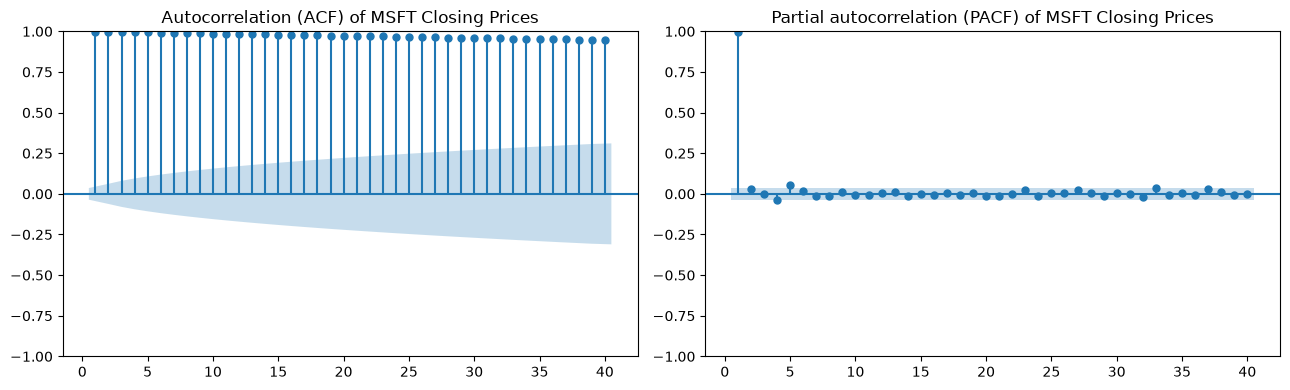

In [39]:
# ACF AND PACF for closing prices
plot_acf_pacf(
    price,
    lags=40,
    title="of MSFT Closing Prices"
)

- The ACF graph shows a slowly declining positive autocorrelation, meaning that historical MSFT closing prices are strongly related to their previous values.
- The PCF graph shows that most subsequent lags are close to zero. This suggests that the strongest direct relationship is between the current price and the immediately preceding price, after accounting for intermediate lags.

The ACF demonstrates strong persistence in MSFT closing prices, supporting the observation that the original price series is non-stationary.

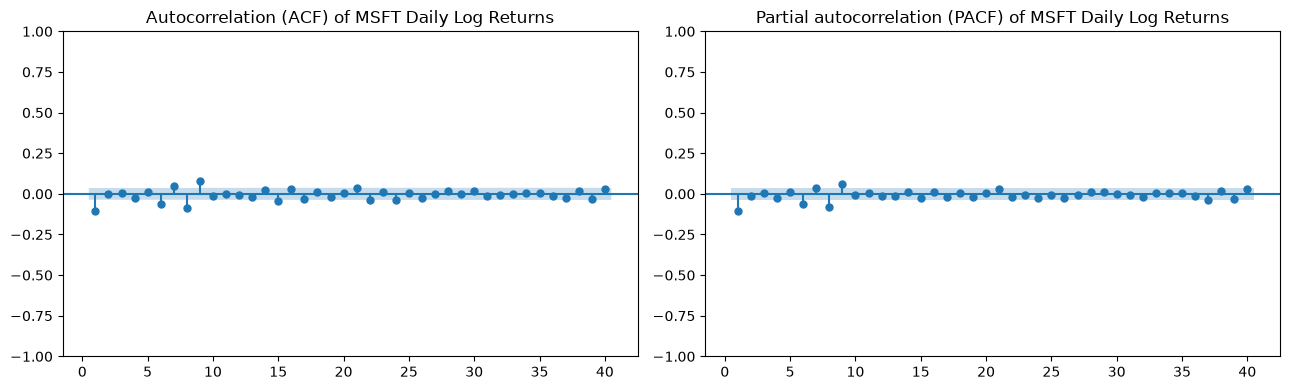

In [40]:
#ACF AND PACF for log returns
plot_acf_pacf(
    log_return,
    lags=40,
    title="of MSFT Daily Log Returns"
)

The ACF and PACF results suggest that log returns are considerably less persistent than stock prices. This supports using log returns as the forecasting target.

### Test log returns
This helps establish whether past returns contain statistically detectable linear information.

In [41]:
ljung_box_results = acorr_ljungbox(
    log_return,
    lags=[5, 10, 21],
    return_df=True
)

ljung_box_results

,lb_stat,lb_pvalue
5,36.132474,8.935828e-07
10,97.851846,1.465235e-16
21,119.563865,8.584504e-16


The Ljung-Box test was conducted to determine whether significant autocorrelation exists in MSFT daily log returns. The results produced p-values below 0.05 at lags 5, 10 and 21. Therefore, the null hypothesis of no autocorrelation is rejected at all three lag levels. This indicates that some statistically significant autocorrelation exists in the daily log returns. Although the ACF and PACF plots show relatively weak individual correlations, the Ljung-Box test demonstrates that the combined autocorrelation across multiple lags is statistically significant.

### Volatility Clustering
Volatility clustering occurs when large stock price movements tend to be followed by other large movements, while smaller movements tend to occur in relatively calm periods.

This is different from predicting whether the stock price will increase or decrease.

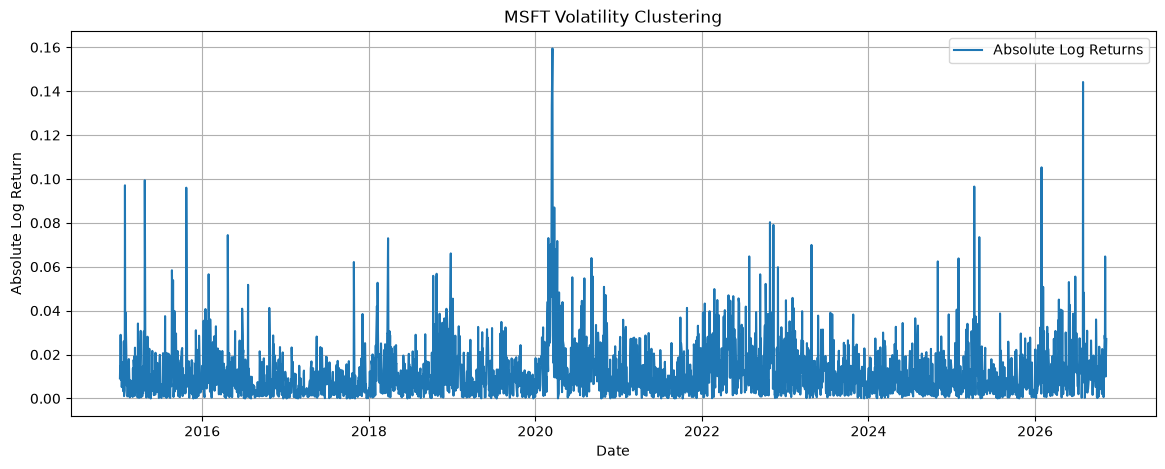

In [42]:
# Plotting the absolute log returns
plt.figure(figsize=(14, 5))

plt.plot(
    log_return.abs(),
    label="Absolute Log Returns"
)

plt.title("MSFT Volatility Clustering")
plt.xlabel("Date")
plt.ylabel("Absolute Log Return")

plt.legend()
plt.grid(True)
plt.show()

The absolute log returns graph shows that MSFT experiences periods of high and low volatility rather than maintaining a constant level of price fluctuations. Large movements are clustered around certain periods, particularly 2020, with other noticeable increases around 2018–2019, 2022–2023 and 2025–2026. These patterns indicate volatility clustering, where periods of large price movements tend to be followed by further large movements, while relatively calm periods tend to be followed by smaller movements. This suggests that market volatility exhibits persistence over time.

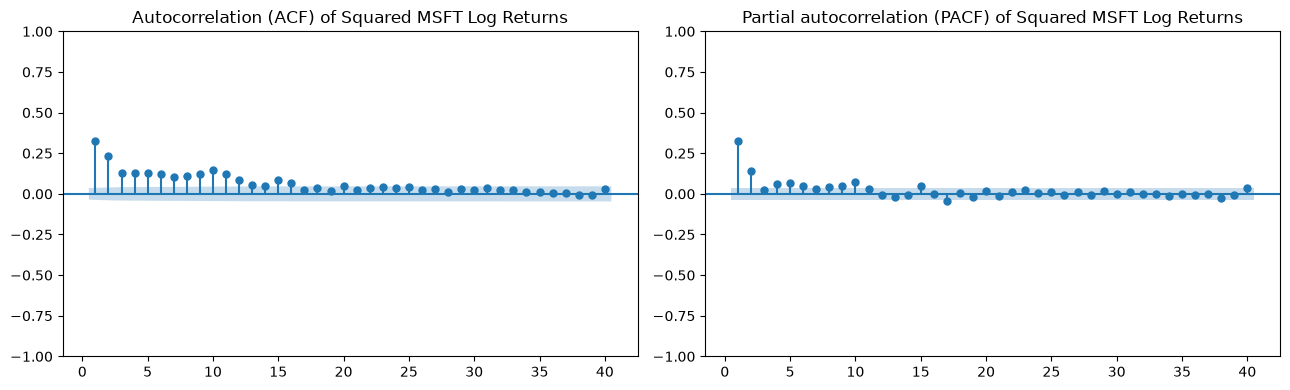

In [43]:
# Examine squared returns
squared_returns = log_return ** 2

plot_acf_pacf(
    squared_returns,
    lags=40,
    title="of Squared MSFT Log Returns"
)

The ACF plot of squared MSFT log returns displays strong positive autocorrelation at the first few lags, followed by a gradual decline. Several autocorrelation values remain outside the confidence bands, indicating statistically noticeable relationships between past and current squared returns. The PACF plot also shows a strong spike at lag 1 and additional smaller significant spikes. These findings suggest that the magnitude of stock price movements is dependent on previous movements, providing further evidence of volatility clustering. This demonstrates that volatility can exhibit persistence even when ordinary daily returns have relatively weak autocorrelation.

In [44]:
# Ljung-Box test on squared returns
squared_ljung_box = acorr_ljungbox(
    squared_returns,
    lags=[5, 10, 21],
    return_df=True
)

squared_ljung_box

,lb_stat,lb_pvalue
5,625.382298,6.623359e-133
10,845.836816,2.869469e-175
21,978.023866,1.341271e-193


The Ljung-Box test on squared log returns produced extremely small p-values at lags 5, 10 and 21. Therefore, the null hypothesis of no autocorrelation is rejected at all three lag levels. These results provide strong statistical evidence that squared returns are autocorrelated. This suggests that the magnitude of daily stock price movements is related to previous movements, confirming the presence of volatility clustering in the MSFT dataset.

### GARCH(1,1) volatility modelling
It examines how volatility changes over time.

In [45]:
# Fit GARCH(1,1)
returns_pct = log_return * 100

garch = arch_model(
    returns_pct,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

garch_fit = garch.fit(disp="off")

print(garch_fit.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                        Close   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -5381.35
Distribution:      Standardized Student's t   AIC:                           10772.7
Method:                  Maximum Likelihood   BIC:                           10802.7
                                              No. Observations:                 2980
Date:                      Fri, Nov 20 2026   Df Residuals:                     2979
Time:                              16:22:20   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

The GARCH(1,1) model was used to examine the changing volatility of MSFT daily returns. The estimated Alpha coefficient was 0.1297, while the Beta coefficient was 0.8513. Their combined value of 0.9810 indicates a high degree of volatility persistence. This means that recent market shocks and previous volatility have a considerable influence on current volatility. The conditional volatility graph shows that the GARCH model captures periods of increased and decreased market uncertainty, particularly around 2020 and other periods of market fluctuations. Therefore, the results demonstrate that MSFT volatility changes over time and that previous volatility contains useful information for estimating current market risk.

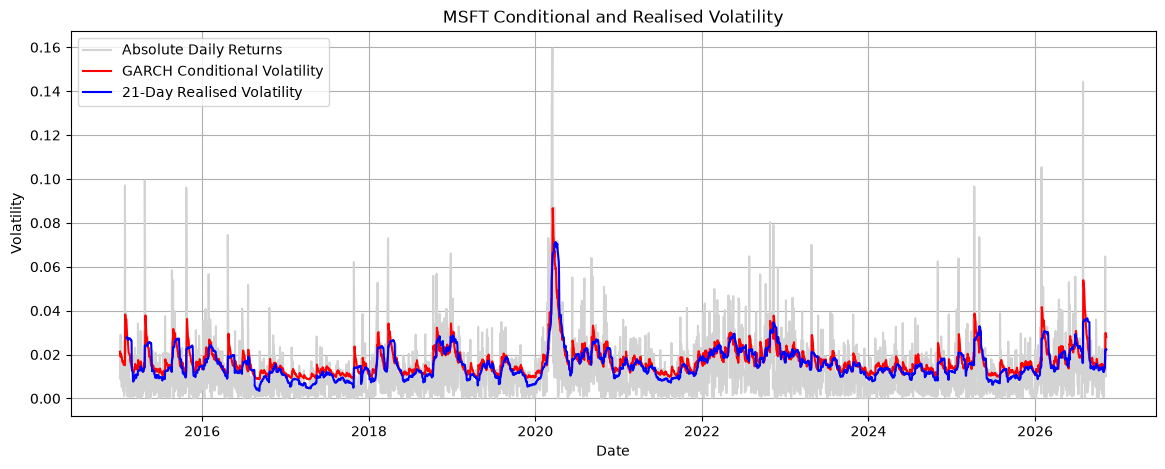

In [ ]:
# Plotting conditional volatility
# The graph helps demonstrate whether GARCH conditional volatility follows periods of increased and decreased market turbulence.
conditional_vol = garch_fit.conditional_volatility / 100

realised_vol = log_return.rolling(21).std()

plt.figure(figsize=(14, 5))

plt.plot(
    log_return.abs(),
    color="lightgrey",
    label="Absolute Daily Returns"
)

plt.plot(
    conditional_vol,
    color="red",
    label="GARCH Conditional Volatility"
)

plt.plot(
    realised_vol,
    color="blue",
    label="21-Day Realised Volatility"
)

plt.title("MSFT Conditional and Realised Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")

plt.legend()
plt.grid(True)
plt.show()

### Overall Conclusion

The analysis of Microsoft's (MSFT) historical stock data revealed important differences between closing prices and daily log returns. The rolling statistics showed that closing prices exhibit a changing mean and variance, while daily log returns fluctuate around a relatively stable mean.

The Augmented Dickey-Fuller (ADF) and KPSS tests confirmed that the closing price and log closing price are non-stationary, whereas the first-differenced prices and daily log returns are stationary according to the two tests. The ACF and PACF analysis further demonstrated that closing prices have strong autocorrelation, while daily log returns exhibit considerably weaker autocorrelation.

However, the Ljung-Box tests revealed statistically significant autocorrelation in both ordinary and squared log returns. The strong autocorrelation in squared returns, together with the absolute return plots, provided evidence of volatility clustering. Furthermore, the GARCH(1,1) model produced a volatility persistence estimate of 0.9810, indicating that volatility shocks have lasting effects.

Overall, the findings support the use of daily log returns rather than raw closing prices as the target variable for subsequent forecasting models. They also demonstrate that although return direction may be difficult to predict, volatility exhibits persistence and should be considered when estimating forecasting uncertainty.